<a href="https://colab.research.google.com/github/Tdhairya2325/UAV-Intelligence-System/blob/main/notebooks/01_data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

In [16]:
import glob
import os

RAW_DIR = "/content/drive/MyDrive/UAV-Intelligence-System/data/raw"

train_matches = glob.glob(
    os.path.join(RAW_DIR, "VisDrone2019-DET-train*")
)

val_matches = glob.glob(
    os.path.join(RAW_DIR, "VisDrone2019-DET-val*")
)

TRAIN_DIR = train_matches[0]
VAL_DIR = val_matches[0]

print("Training path:", TRAIN_DIR)
print("Validation path:", VAL_DIR)

Training path: /content/drive/MyDrive/UAV-Intelligence-System/data/raw/VisDrone2019-DET-train
Validation path: /content/drive/MyDrive/UAV-Intelligence-System/data/raw/VisDrone2019-DET-val


In [17]:
def inspect_dataset(dataset_dir):

    image_dir = os.path.join(dataset_dir, "images")
    annotation_dir = os.path.join(dataset_dir, "annotations")

    images = glob.glob(os.path.join(image_dir, "*.jpg"))
    annotations = glob.glob(os.path.join(annotation_dir, "*.txt"))

    print("\nDataset:", os.path.basename(dataset_dir))
    print("Total images:", len(images))
    print("Total annotations:", len(annotations))
    print("-" * 40)

    return images, annotations


train_images, train_annotations = inspect_dataset(TRAIN_DIR)

val_images, val_annotations = inspect_dataset(VAL_DIR)


Dataset: VisDrone2019-DET-train
Total images: 6471
Total annotations: 6471
----------------------------------------

Dataset: VisDrone2019-DET-val
Total images: 548
Total annotations: 548
----------------------------------------


In [11]:
print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Validation folder exists:", os.path.exists(VAL_DIR))

Training folder exists: True
Validation folder exists: True


Image dimensions: (1050, 1400, 3)
Image data type: uint8


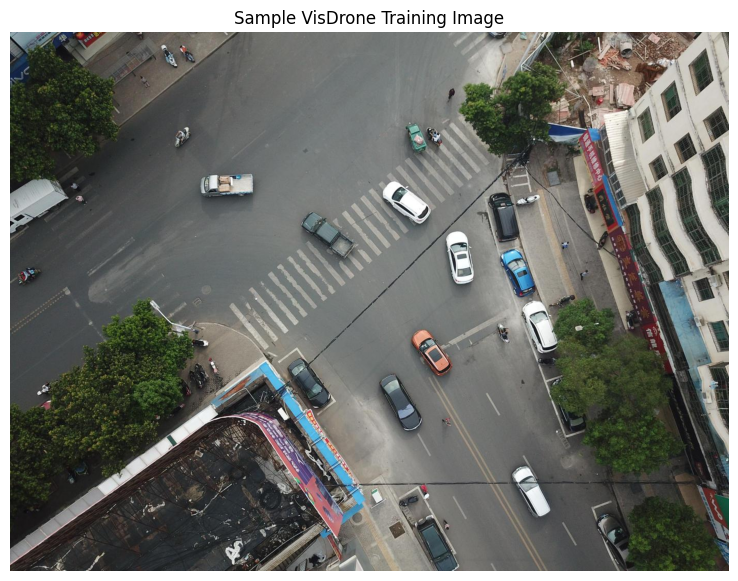

In [18]:
import cv2
import matplotlib.pyplot as plt

image_path = train_images[0]

image = cv2.imread(image_path)

print("Image dimensions:", image.shape)
print("Image data type:", image.dtype)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title("Sample VisDrone Training Image")
plt.axis("off")
plt.show()

In [19]:
import pandas as pd

columns = [
    "left",
    "top",
    "width",
    "height",
    "score",
    "category",
    "truncation",
    "occlusion"
]

sample_annotation = train_annotations[0]

df = pd.read_csv(
    sample_annotation,
    header=None,
    names=columns
)

print(df.head())
print("\nTotal objects:", len(df))

   left  top  width  height  score  category  truncation  occlusion
0   842  950     13      19      1         1           0          0
1   805  897     10      13      1         1           0          0
2   953  577     17      18      1         2           0          0
3  1110  460     16      25      1         1           0          0
4  1073  405     15      21      1         1           0          1

Total objects: 52


# **Understand the complete dataset**

In [20]:
class_names = {
    1: "Pedestrian",
    2: "People",
    3: "Bicycle",
    4: "Car",
    5: "Van",
    6: "Truck",
    7: "Tricycle",
    8: "Awning-tricycle",
    9: "Bus",
    10: "Motor"
}

Only one Annotation file has 9 columns

In [23]:
from collections import Counter

column_counts = Counter()

for file in train_annotations:
    try:
        temp = pd.read_csv(file, header=None)
        column_counts[temp.shape[1]] += 1

    except pd.errors.EmptyDataError:
        pass

print("Annotation files grouped by column count:")
print(column_counts)

Annotation files grouped by column count:
Counter({8: 6470, 9: 1})


In [24]:
for file in train_annotations:
    try:
        temp = pd.read_csv(file, header=None)

        if temp.shape[1] != 8:
            print("\nFile:", os.path.basename(file))
            print("Columns:", temp.shape[1])
            print(temp.head())

    except pd.errors.EmptyDataError:
        pass


File: 9999974_00000_d_0000053.txt
Columns: 9
     0    1    2    3  4   5  6  7   8
0  440  541  271  152  1   6  0  0 NaN
1  436  772  134   72  1   5  0  0 NaN
2  601  713   60   39  1  10  0  0 NaN
3  486  706  102   59  1   8  0  0 NaN
4  397  978  167   90  1   4  0  0 NaN


# **All Annotations list**

In [25]:
all_annotations = []

for file in train_annotations:

    try:
        temp = pd.read_csv(file, header=None)

        # Remove columns that are completely empty
        temp = temp.dropna(axis=1, how="all")

        # Keep only files with the expected 8 columns
        if temp.shape[1] == 8:
            all_annotations.append(temp)
        else:
            print("Unexpected format:", os.path.basename(file))

    except pd.errors.EmptyDataError:
        continue

# Combine all annotation files
annotations_df = pd.concat(all_annotations, ignore_index=True)

# Assign column names
annotations_df.columns = [
    "left", "top", "width", "height",
    "score", "category", "truncation", "occlusion"
]

print("Total annotation rows:", len(annotations_df))
print("\nFirst five rows:")
print(annotations_df.head())

print("\nDataFrame shape:", annotations_df.shape)

Total annotation rows: 353550

First five rows:
   left  top  width  height  score  category  truncation  occlusion
0   842  950     13      19      1         1           0          0
1   805  897     10      13      1         1           0          0
2   953  577     17      18      1         2           0          0
3  1110  460     16      25      1         1           0          0
4  1073  405     15      21      1         1           0          1

DataFrame shape: (353550, 8)


# **Class Distribution**

In [26]:
valid_objects = annotations_df[
    (annotations_df["score"] == 1) &
    (annotations_df["category"].isin(class_names.keys()))
].copy()

class_distribution = (
    valid_objects["category"]
    .value_counts()
    .reindex(class_names.keys(), fill_value=0)
)

class_distribution.index = class_distribution.index.map(class_names)

print(class_distribution)

category
Pedestrian          79337
People              27059
Bicycle             10480
Car                144867
Van                 24956
Truck               12875
Tricycle             4812
Awning-tricycle      3246
Bus                  5926
Motor               29647
Name: count, dtype: int64
